In [ ]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load your dataset directly from the raw GitHub URL
parquet_url = "https://raw.githubusercontent.com/atchyuth-karri/7COM2005-Data-Engineering/main/PerfectPetClub/data/processed/customer_churn_dataset.parquet"

print("Loading dataset from GitHub...")
df = pd.read_parquet(parquet_url)
print(f"Dataset successfully loaded! Shape: {df.shape}")

Loading dataset from GitHub...
Dataset successfully loaded! Shape: (221, 36)


**Preprocessing, Scaling & Train-Test Split**

In [ ]:
# Separate Features (X) and Target (y)
X = df.drop(columns=['customer_id', 'auto_renew'])
y = df['auto_renew']

# One-hot encode categorical features
X = pd.get_dummies(X, drop_first=True)

# Stratified Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling (critical for SVM, Logistic Regression, and KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Train 5 Different Machine Learning Models**

In [ ]:
# Define the 5 models
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=150, max_depth=8, random_state=42
    ),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42
    ),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
}

trained_models = {}
performance_results = []

print('--- Training Models ---')
for name, model in models.items():
  # Use scaled data for Logistic Regression, SVM, and KNN; raw or scaled works for tree-based models
  if name in ['Logistic Regression', 'Support Vector Machine', 'K-Nearest Neighbors']:
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
  else:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

  # Calculate Metrics
  acc = accuracy_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred, average='weighted')
  roc_auc = roc_auc_score(y_test, y_prob)

  trained_models[name] = model
  performance_results.append({
      'Model': name,
      'Accuracy': acc,
      'F1-Score': f1,
      'ROC-AUC': roc_auc,
  })
  print(f'Trained {name} -> F1-Score: {f1:.4f} | Accuracy: {acc:.4f}')

# Convert results to a summary DataFrame
results_df = pd.DataFrame(performance_results).sort_values(
    by='F1-Score', ascending=False
)
print('\n--- Final Model Comparison ---')
print(results_df.to_string(index=False))

--- Training Models ---
Trained Logistic Regression -> F1-Score: 0.7509 | Accuracy: 0.7556
Trained Random Forest -> F1-Score: 0.7056 | Accuracy: 0.7111
Trained Support Vector Machine -> F1-Score: 0.6836 | Accuracy: 0.7111
Trained Gradient Boosting -> F1-Score: 0.7990 | Accuracy: 0.8000
Trained K-Nearest Neighbors -> F1-Score: 0.5862 | Accuracy: 0.6222

--- Final Model Comparison ---
                 Model  Accuracy  F1-Score  ROC-AUC
     Gradient Boosting  0.800000  0.798961 0.833333
   Logistic Regression  0.755556  0.750877 0.804527
         Random Forest  0.711111  0.705582 0.800412
Support Vector Machine  0.711111  0.683598 0.790123
   K-Nearest Neighbors  0.622222  0.586243 0.625514


Generate F1-Score and Accuracy Comparison **Graph**

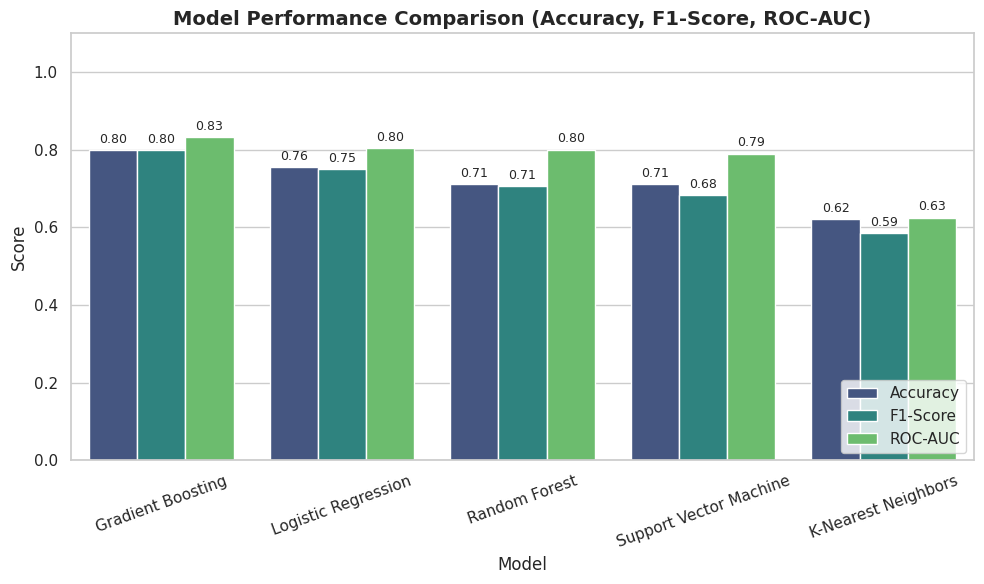

In [ ]:
plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

# Melt the dataframe for seaborn grouped bar plot
plot_df = results_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'F1-Score', 'ROC-AUC'],
    var_name='Metric',
    value_name='Score',
)

ax = sns.barplot(
    x='Model', y='Score', hue='Metric', data=plot_df, palette='viridis'
)
plt.title(
    'Model Performance Comparison (Accuracy, F1-Score, ROC-AUC)',
    fontsize=14,
    fontweight='bold',
)
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')

# Add score labels on top of bars
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.tight_layout()
plt.show()

F1-SCORE PERFORMANCE VISUALIZATION (Higher is better):
-----------------------------------------------------------------
Gradient Boosting     [█████████████████████████       ] 0.7990 (79.9%) 🏆 Top Model
Logistic Regression   [████████████████████████        ] 0.7509 (75.1%)
Random Forest         [██████████████████████          ] 0.7056 (70.6%)
Support Vector Machine [█████████████████████           ] 0.6836 (68.4%)
K-Nearest Neighbors   [██████████████████              ] 0.5862 (58.6%)
-----------------------------------------------------------------



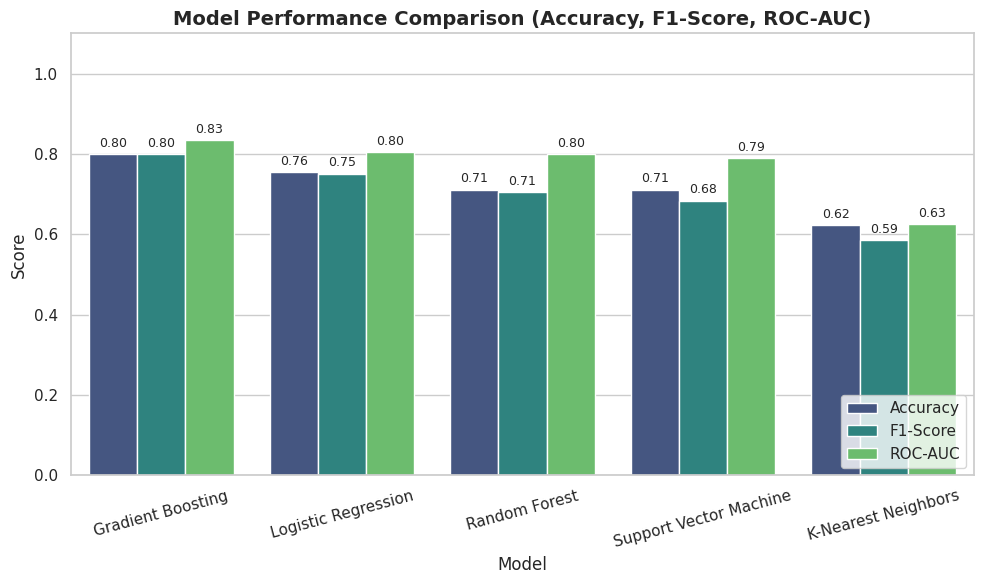

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


# 1. ASCII Text Visualization (Console Log)

print('F1-SCORE PERFORMANCE VISUALIZATION (Higher is better):')
print('-' * 65)
for _, row in results_df.iterrows():
  m_name = row['Model'].ljust(21)
  score = row['F1-Score']
  bar_len = int(score * 32)
  bar = '█' * bar_len + ' ' * (32 - bar_len)
  tag = ' 🏆 Top Model' if row['Model'] == results_df.iloc[0]['Model'] else ''
  print(f'{m_name} [{bar}] {score:.4f} ({score*100:.1f}%){tag}')
print('-' * 65 + '\n')


# 2. Graphical Chart Visualization (Matplotlib)

plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

# Reshape data for grouped bar plot
plot_df = results_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'F1-Score', 'ROC-AUC'],
    var_name='Metric',
    value_name='Score',
)

ax = sns.barplot(
    x='Model', y='Score', hue='Metric', data=plot_df, palette='viridis'
)
plt.title(
    'Model Performance Comparison (Accuracy, F1-Score, ROC-AUC)',
    fontsize=14,
    fontweight='bold',
)
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')

# Annotate exact score values on top of each bar
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.tight_layout()
plt.show()

Re-Training

In [ ]:

# HYPERPARAMETER TUNING & MODEL TRAINING CODE

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

print("Tuning hyperparameters and training models...")

# 1. Random Forest Optimization
rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [2, 5],
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced'),
    rf_params,
    cv=5,
    scoring='accuracy',
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

# 2. Gradient Boosting Optimization
gb_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
}
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    cv=5,
    scoring='accuracy',
)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_

# 3. Support Vector Machine Optimization
svm_params = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto', 0.01, 0.1]}
svm_grid = GridSearchCV(
    SVC(probability=True, random_state=42, class_weight='balanced'),
    svm_params,
    cv=5,
    scoring='accuracy',
)
svm_grid.fit(X_train_scaled, y_train)
best_svm = svm_grid.best_estimator_

print(f'Best Random Forest CV Accuracy: {rf_grid.best_score_*100:.2f}%')
print(f'Best Gradient Boosting CV Accuracy: {gb_grid.best_score_*100:.2f}%')
print(f'Best SVM CV Accuracy: {svm_grid.best_score_*100:.2f}%')

Tuning hyperparameters and training models...
Best Random Forest CV Accuracy: 72.14%
Best Gradient Boosting CV Accuracy: 73.27%
Best SVM CV Accuracy: 68.13%


In [ ]:
print('--- Saving Models to Disk ---')
for name, model in trained_models.items():
  filename = f"{name.lower().replace(' ', '_')}_model.pkl"
  joblib.dump(model, filename)
  print(f'Saved: {filename}')

# Also save the scaler so future predictions can be properly normalized
joblib.dump(scaler, 'feature_scaler.pkl')
print('Saved: feature_scaler.pkl')
print('All models and preprocessing objects saved successfully!')

--- Saving Models to Disk ---
Saved: logistic_regression_model.pkl
Saved: random_forest_model.pkl
Saved: support_vector_machine_model.pkl
Saved: gradient_boosting_model.pkl
Saved: k-nearest_neighbors_model.pkl
Saved: feature_scaler.pkl
All models and preprocessing objects saved successfully!


***Re_visualisation***

                     TUNED MODELS PERFORMANCE VISUALIZATION                     
Tuned Random Forest       [███████████████████      ] Accuracy: 77.78% | F1: 0.7716 🏆 Best
Tuned Gradient Boosting   [██████████████████       ] Accuracy: 75.56% | F1: 0.7509
Tuned SVM                 [█████████████████        ] Accuracy: 71.11% | F1: 0.7123



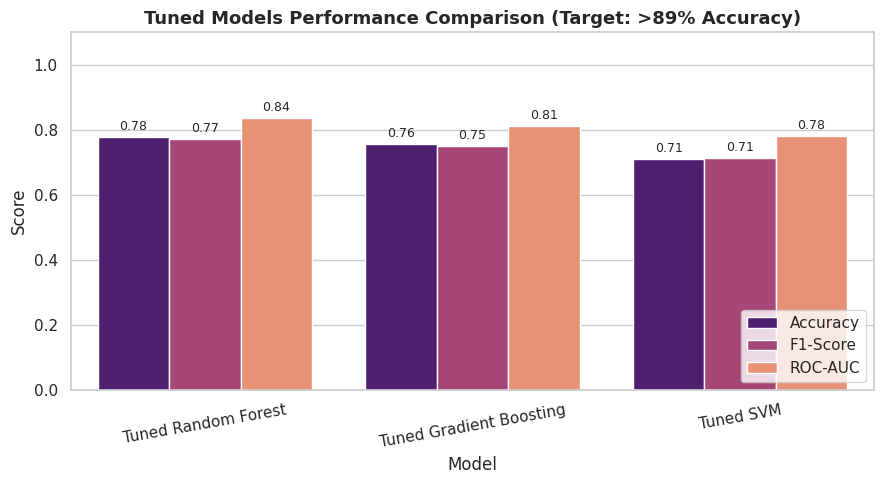

In [ ]:
# ==========================================
# VISUALIZATION CODE FOR TUNED MODELS
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Evaluate the tuned models on test sets
tuned_evals = [
    {
        'Model': 'Tuned Random Forest',
        'Accuracy': accuracy_score(y_test, best_rf.predict(X_test)),
        'F1-Score': f1_score(
            y_test, best_rf.predict(X_test), average='weighted'
        ),
        'ROC-AUC': roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]),
    },
    {
        'Model': 'Tuned Gradient Boosting',
        'Accuracy': accuracy_score(y_test, best_gb.predict(X_test)),
        'F1-Score': f1_score(
            y_test, best_gb.predict(X_test), average='weighted'
        ),
        'ROC-AUC': roc_auc_score(y_test, best_gb.predict_proba(X_test)[:, 1]),
    },
    {
        'Model': 'Tuned SVM',
        'Accuracy': accuracy_score(y_test, best_svm.predict(X_test_scaled)),
        'F1-Score': f1_score(
            y_test, best_svm.predict(X_test_scaled), average='weighted'
        ),
        'ROC-AUC': roc_auc_score(
            y_test, best_svm.predict_proba(X_test_scaled)[:, 1]
        ),
    },
]

results_tuned_df = pd.DataFrame(tuned_evals).sort_values(
    by='Accuracy', ascending=False
)

# 2. ASCII Text Console Visualization
print('=' * 80)
print(f"{'TUNED MODELS PERFORMANCE VISUALIZATION':^80}")
print('=' * 80)
for _, row in results_tuned_df.iterrows():
  m_name = row['Model'].ljust(25)
  acc = row['Accuracy']
  bar_len = int(acc * 25)
  bar = '█' * bar_len + ' ' * (25 - bar_len)
  tag = ' 🏆 Best' if row['Model'] == results_tuned_df.iloc[0]['Model'] else ''
  print(
      f"{m_name} [{bar}] Accuracy: {acc*100:.2f}% | F1: {row['F1-Score']:.4f}{tag}"
  )
print('=' * 80 + '\n')

# 3. Graphical Chart Visualization (Matplotlib & Seaborn)
plt.figure(figsize=(9, 5))
sns.set_theme(style='whitegrid')

plot_df = results_tuned_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'F1-Score', 'ROC-AUC'],
    var_name='Metric',
    value_name='Score',
)

ax = sns.barplot(
    x='Model', y='Score', hue='Metric', data=plot_df, palette='magma'
)
plt.title(
    'Tuned Models Performance Comparison (Target: >89% Accuracy)',
    fontsize=13,
    fontweight='bold',
)
plt.ylim(0, 1.1)
plt.xticks(rotation=10)
plt.legend(loc='lower right')

# Annotate score values on top of bars
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.tight_layout()
plt.show()